ADABOOST - Melhores parâmetros: {'modelo__estimator__max_depth': 3, 'modelo__learning_rate': 0.5, 'modelo__n_estimators': 200}
           Treino   Teste  Validação Cruzada  Dif. Treino-Teste  Dif. Treino-CV  Dif. Teste-CV
Acurácia   0.9392  0.8958             0.8427             0.0434          0.0965         0.0531
Recall     0.9211  0.7385             0.6118             0.1826          0.3092         0.1266
Precision  0.7143  0.5926             0.4481             0.1217          0.2662         0.1445
F1         0.8046  0.6575             0.5140             0.1471          0.2906         0.1435


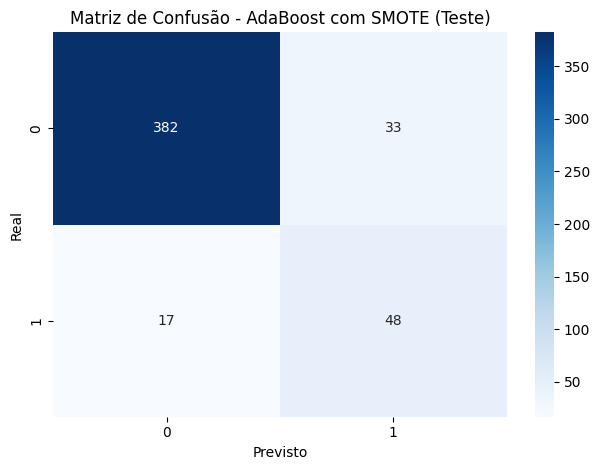

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold, GridSearchCV
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, confusion_matrix
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

# 1. Dados (quality removida: NOTA foi criada a partir dela, causaria vazamento)
df = pd.read_csv("nota_vinho.csv")
X = df.drop(columns=["NOTA", "quality"])
y = df["NOTA"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

# 2. Pipeline: SMOTE (balanceamento) + AdaBoost

pipe = Pipeline([
    ("smote", SMOTE(random_state=42)),
    ("modelo", AdaBoostClassifier(estimator=DecisionTreeClassifier(), random_state=42)),
])

# 3. Busca dos melhores parâmetros (otimizando F1)
param_grid = {
    "modelo__n_estimators": [100, 200, 300],
    "modelo__learning_rate": [0.05, 0.1, 0.5, 1.0],
    "modelo__estimator__max_depth": [1, 2, 3],
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
busca = GridSearchCV(pipe, param_grid, scoring="f1", cv=cv, n_jobs=-1)
busca.fit(X_train, y_train)
modelo = busca.best_estimator_
print("ADABOOST - Melhores parâmetros:", busca.best_params_)

# 4. Validação cruzada do melhor modelo (sobre o treino)
scoring = ["accuracy", "recall", "precision", "f1"]
cv_res = cross_validate(modelo, X_train, y_train, cv=cv, scoring=scoring)

# 5. Métricas
def metricas(y_real, y_pred):
    return {"Acurácia": accuracy_score(y_real, y_pred),
            "Recall": recall_score(y_real, y_pred),
            "Precision": precision_score(y_real, y_pred),
            "F1": f1_score(y_real, y_pred)}

tabela = pd.DataFrame({
    "Treino": metricas(y_train, modelo.predict(X_train)),
    "Teste": metricas(y_test, modelo.predict(X_test)),
    "Validação Cruzada": {"Acurácia": cv_res["test_accuracy"].mean(),
                          "Recall": cv_res["test_recall"].mean(),
                          "Precision": cv_res["test_precision"].mean(),
                          "F1": cv_res["test_f1"].mean()},
})
tabela["Dif. Treino-Teste"] = tabela["Treino"] - tabela["Teste"]
tabela["Dif. Treino-CV"] = tabela["Treino"] - tabela["Validação Cruzada"]
tabela["Dif. Teste-CV"] = tabela["Teste"] - tabela["Validação Cruzada"]
print(tabela.round(4).to_string())

# 6. Matriz de confusão (teste)
cm = confusion_matrix(y_test, modelo.predict(X_test))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=[0, 1], yticklabels=[0, 1])
plt.title("Matriz de Confusão - AdaBoost com SMOTE (Teste)")
plt.xlabel("Previsto")
plt.ylabel("Real")
plt.tight_layout()
plt.savefig("matriz_confusao_adaboost.png", dpi=120)
plt.show()


Importância das variáveis:
alcohol                 0.1971
free sulfur dioxide     0.1132
total sulfur dioxide    0.1108
residual sugar          0.0948
volatile acidity        0.0850
sulphates               0.0778
fixed acidity           0.0721
density                 0.0675
pH                      0.0671
citric acid             0.0650
chlorides               0.0495


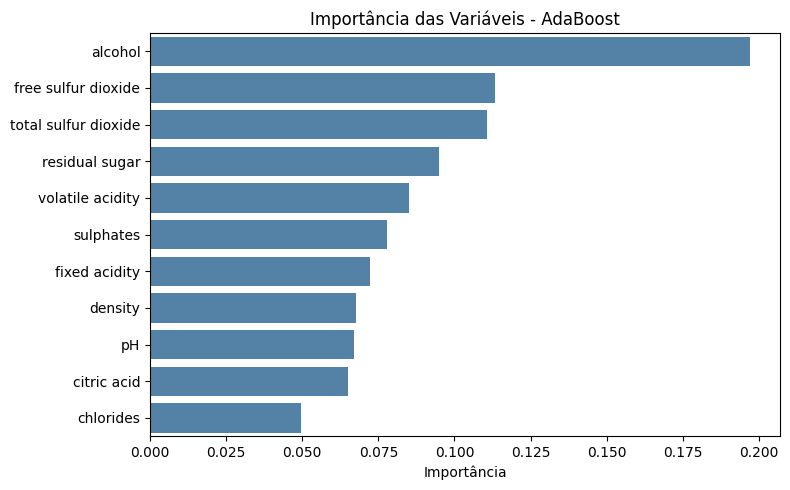

In [4]:

# 7. Importância das variáveis
importancia = pd.Series(modelo.named_steps["modelo"].feature_importances_,
                        index=X.columns).sort_values(ascending=False)
print("\nImportância das variáveis:")
print(importancia.round(4).to_string())
 
plt.figure(figsize=(8, 5))
sns.barplot(x=importancia.values, y=importancia.index, color="steelblue")
plt.title("Importância das Variáveis - AdaBoost")
plt.xlabel("Importância")
plt.ylabel("")
plt.tight_layout()
plt.savefig("importancia_adaboost.png", dpi=120)
plt.show()

GRADIENT BOOSTING - Melhores parâmetros: {'modelo__learning_rate': 0.1, 'modelo__max_depth': 3, 'modelo__min_samples_leaf': 5, 'modelo__n_estimators': 200, 'modelo__subsample': 0.8}
           Treino   Teste  Validação Cruzada  Dif. Treino-Teste  Dif. Treino-CV  Dif. Teste-CV
Acurácia   0.9643  0.9062             0.8517             0.0580          0.1126         0.0546
Recall     0.9342  0.7077             0.5991             0.2265          0.3351         0.1086
Precision  0.8256  0.6389             0.4724             0.1867          0.3532         0.1665
F1         0.8765  0.6715             0.5245             0.2050          0.3520         0.1470


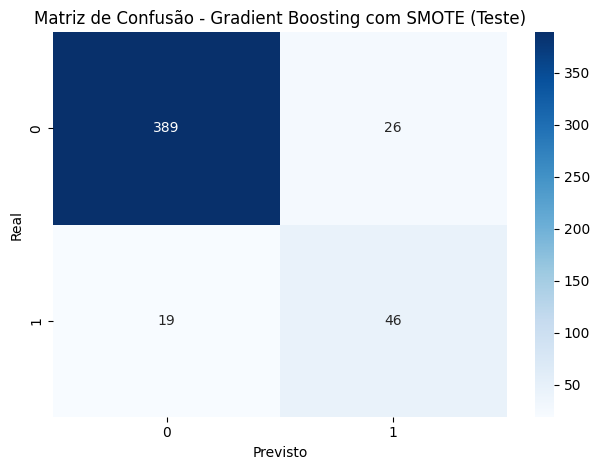

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold, GridSearchCV
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, confusion_matrix
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

# 1. Dados (quality removida: NOTA foi criada a partir dela, causaria vazamento)
df = pd.read_csv("nota_vinho.csv")
X = df.drop(columns=["NOTA", "quality"])
y = df["NOTA"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

# 2. Pipeline: SMOTE (balanceamento) + Gradient Boosting
#    O SMOTE fica dentro do pipeline, então só é aplicado nos dados de treino de cada fold
pipe = Pipeline([
    ("smote", SMOTE(random_state=42)),
    ("modelo", GradientBoostingClassifier(random_state=42)),
])

# 3. Busca dos melhores parâmetros (otimizando F1)
param_grid = {
    "modelo__n_estimators": [100, 200],
    "modelo__learning_rate": [0.05, 0.1],
    "modelo__max_depth": [2, 3, 4],
    "modelo__subsample": [0.8],
    "modelo__min_samples_leaf": [5, 10, 20],
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
busca = GridSearchCV(pipe, param_grid, scoring="f1", cv=cv, n_jobs=-1)
busca.fit(X_train, y_train)
modelo = busca.best_estimator_
print("GRADIENT BOOSTING - Melhores parâmetros:", busca.best_params_)

# 4. Validação cruzada do melhor modelo (sobre o treino)
scoring = ["accuracy", "recall", "precision", "f1"]
cv_res = cross_validate(modelo, X_train, y_train, cv=cv, scoring=scoring)

# 5. Métricas
def metricas(y_real, y_pred):
    return {"Acurácia": accuracy_score(y_real, y_pred),
            "Recall": recall_score(y_real, y_pred),
            "Precision": precision_score(y_real, y_pred),
            "F1": f1_score(y_real, y_pred)}

tabela = pd.DataFrame({
    "Treino": metricas(y_train, modelo.predict(X_train)),
    "Teste": metricas(y_test, modelo.predict(X_test)),
    "Validação Cruzada": {"Acurácia": cv_res["test_accuracy"].mean(),
                          "Recall": cv_res["test_recall"].mean(),
                          "Precision": cv_res["test_precision"].mean(),
                          "F1": cv_res["test_f1"].mean()},
})
tabela["Dif. Treino-Teste"] = tabela["Treino"] - tabela["Teste"]
tabela["Dif. Treino-CV"] = tabela["Treino"] - tabela["Validação Cruzada"]
tabela["Dif. Teste-CV"] = tabela["Teste"] - tabela["Validação Cruzada"]
print(tabela.round(4).to_string())

# 6. Matriz de confusão (teste)
cm = confusion_matrix(y_test, modelo.predict(X_test))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=[0, 1], yticklabels=[0, 1])
plt.title("Matriz de Confusão - Gradient Boosting com SMOTE (Teste)")
plt.xlabel("Previsto")
plt.ylabel("Real")
plt.tight_layout()
plt.savefig("matriz_confusao_gradientboosting.png", dpi=120)
plt.show()


Importância das variáveis:
alcohol                 0.4739
sulphates               0.1453
volatile acidity        0.0954
total sulfur dioxide    0.0677
free sulfur dioxide     0.0436
residual sugar          0.0418
fixed acidity           0.0333
chlorides               0.0302
citric acid             0.0248
pH                      0.0223
density                 0.0217


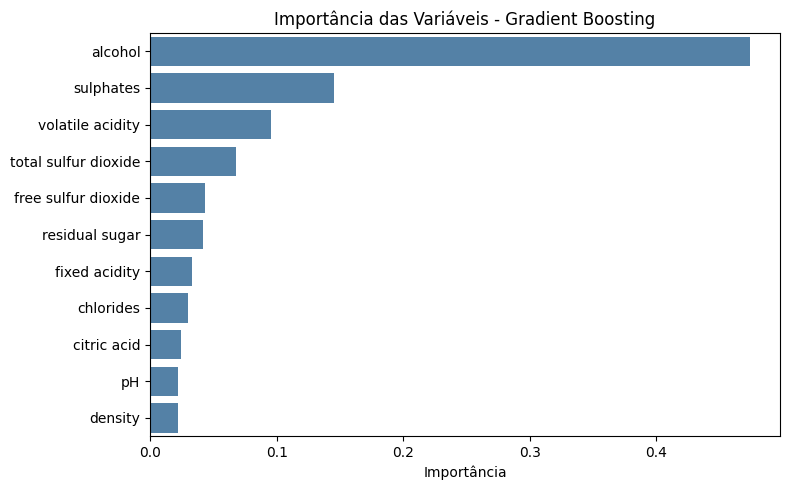

In [6]:
import pandas as pd
# 7. Importância das variáveis
importancia = pd.Series(modelo.named_steps["modelo"].feature_importances_,
                        index=X.columns).sort_values(ascending=False)
print("\nImportância das variáveis:")
print(importancia.round(4).to_string())
 
plt.figure(figsize=(8, 5))
sns.barplot(x=importancia.values, y=importancia.index, color="steelblue")
plt.title("Importância das Variáveis - Gradient Boosting")
plt.xlabel("Importância")
plt.ylabel("")
plt.tight_layout()
plt.savefig("importancia_gradientboosting.png", dpi=120)
plt.show()
 

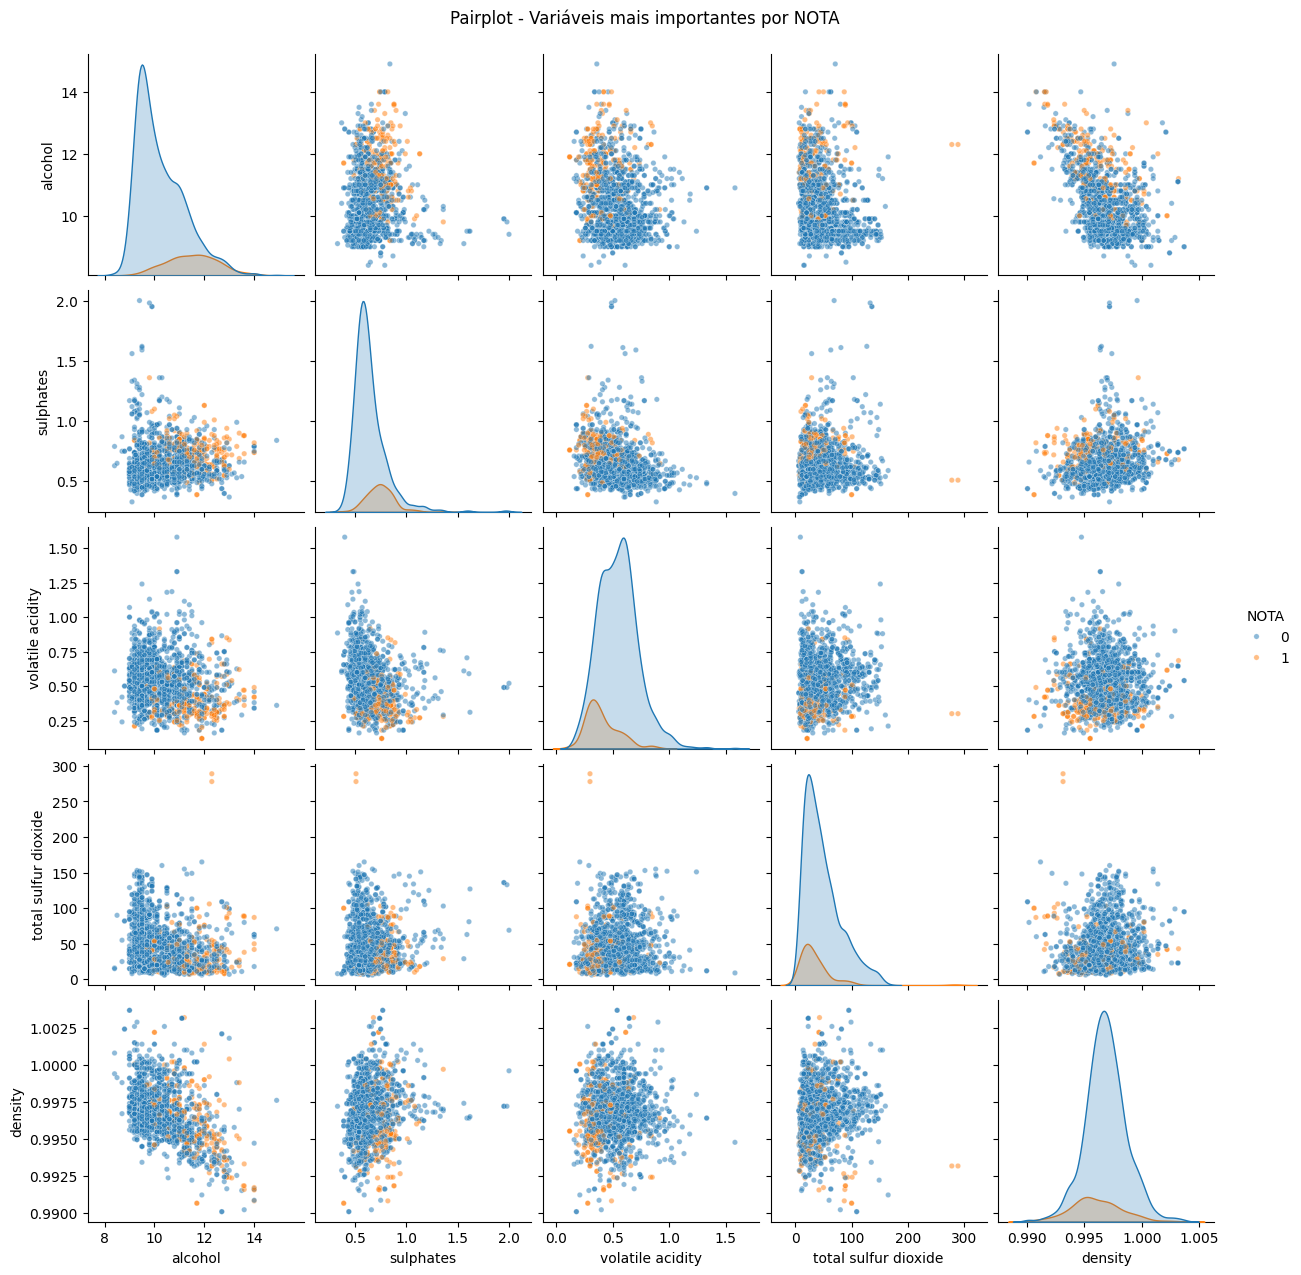

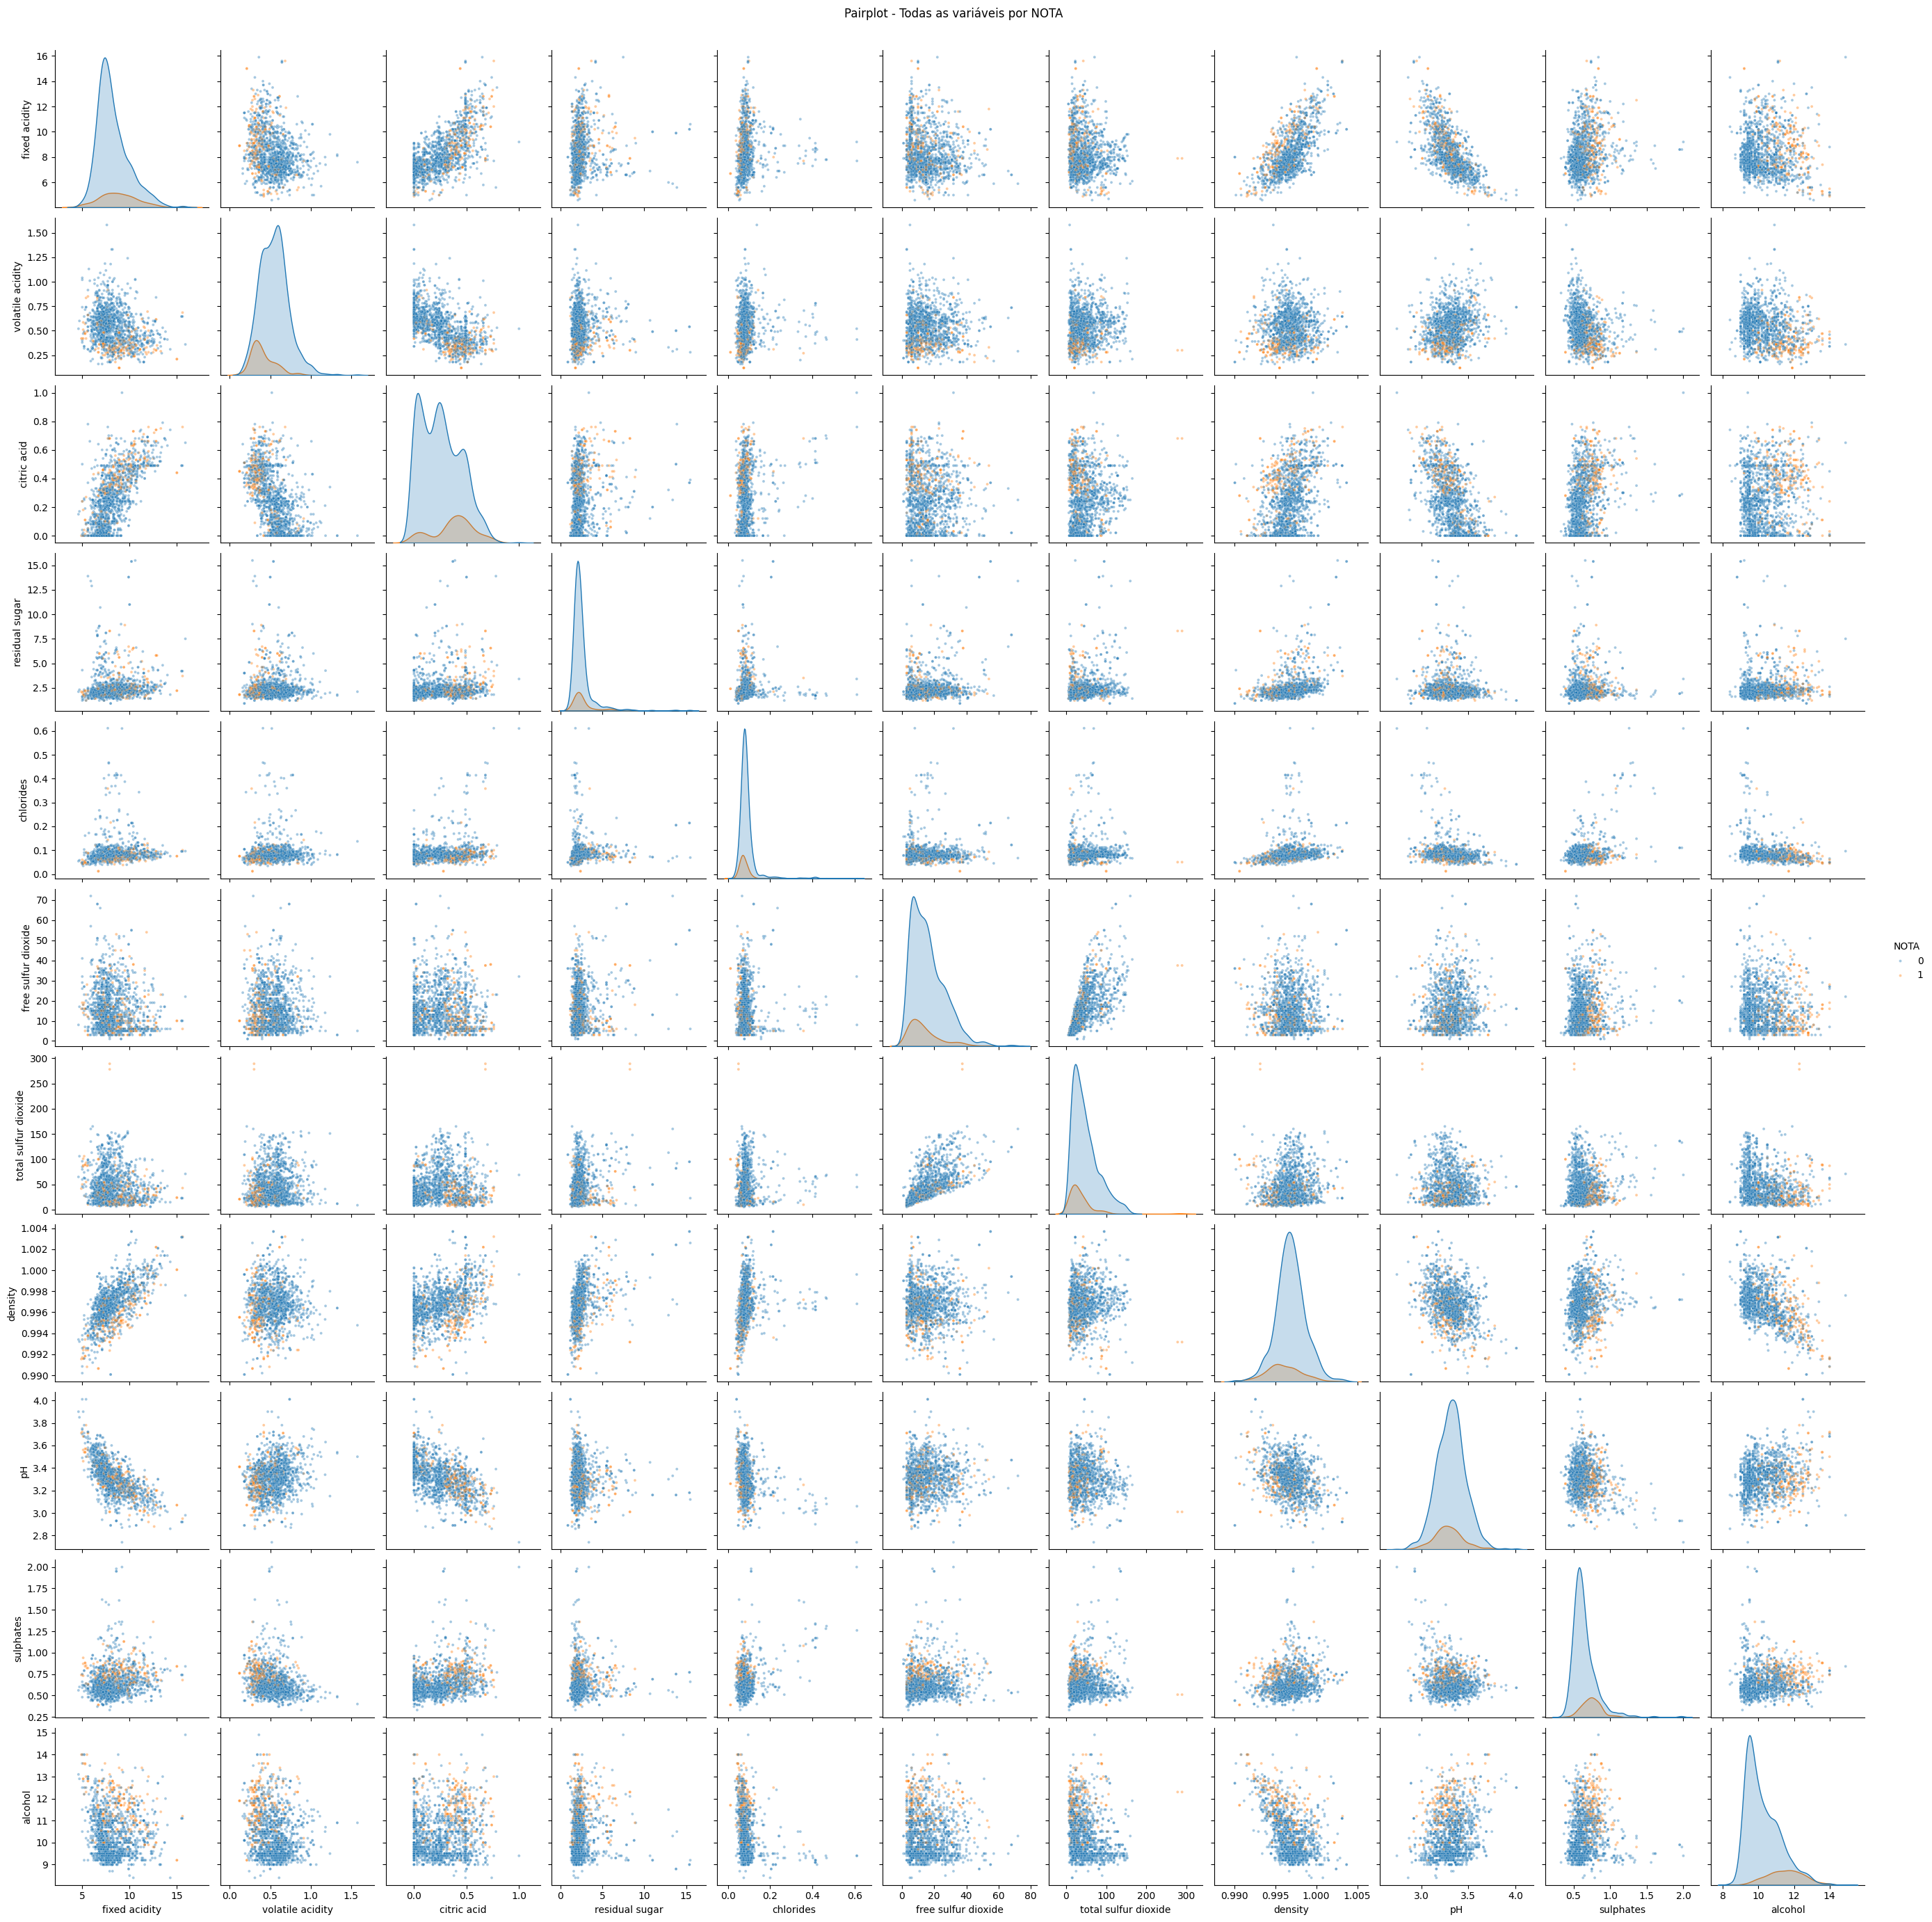

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("nota_vinho.csv").drop(columns=["quality"])  # quality gerou a NOTA

# Pairplot com as 5 variáveis mais importantes dos modelos
top5 = ["alcohol", "sulphates", "volatile acidity", "total sulfur dioxide", "density"]
g = sns.pairplot(df[top5 + ["NOTA"]], hue="NOTA", palette={0: "tab:blue", 1: "tab:orange"},
                 diag_kind="kde", plot_kws={"alpha": 0.5, "s": 15}, corner=False)
g.figure.suptitle("Pairplot - Variáveis mais importantes por NOTA", y=1.02)
g.savefig("pairplot_nota_top5.png", dpi=110, bbox_inches="tight")

# Pairplot com todas as variáveis
g2 = sns.pairplot(df, hue="NOTA", palette={0: "tab:blue", 1: "tab:orange"},
                  diag_kind="kde", plot_kws={"alpha": 0.4, "s": 8})
g2.figure.suptitle("Pairplot - Todas as variáveis por NOTA", y=1.01)
g2.savefig("pairplot_nota_completo.png", dpi=80, bbox_inches="tight")
plt.show()